# 2D Trajectory Plots

Visualize XY trajectories from rollout datasets, starting from the initial position of each clip. Each trajectory is plotted relative to its starting point (origin-centered).

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from scamper.analysis.discriminator.data_loading import (
    load_h5_dataset,
    list_h5_datasets,
)

In [16]:
# ============ CONFIGURATION ============
DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"

# Number of random clips to plot per dataset
NUM_CLIPS = 50

# Random seed for clip selection
SEED = 42

# Datasets to exclude
EXCLUDE_DATASETS = {"original_qpos"}

# Save path
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")

# Display labels
LABEL_MAP = {
    "encoder_decoder_qpos": "Encoder-Decoder",
    "prior_deterministic_qpos": "$\\sigma$=0.00",
    "prior_logvar_-4_qpos": "$\\sigma$=0.14",
    "prior_logvar_-3_qpos": "$\\sigma$=0.22",
    "prior_logvar_-2_qpos": "$\\sigma$=0.37",
    "prior_logvar_-1_qpos": "$\\sigma$=0.61",
    "prior_logvar_-0.5_qpos": "$\\sigma$=0.78",
    "prior_logvar_0_qpos": "$\\sigma$=1.00",
    "prior_predicted_logvar_qpos": "Predicted $\\sigma$",
    "original_qpos": "Original (MoCap)",
}

In [17]:
# Auto-discover datasets and load XY trajectories
available = list_h5_datasets(DATASET_PATH)
datasets_to_plot = [
    ds for ds in available if ds.endswith("_qpos") and ds not in EXCLUDE_DATASETS
]
print(f"Plotting {len(datasets_to_plot)} datasets, {NUM_CLIPS} clips each")

rng = np.random.default_rng(SEED)

trajectories = {}
for name in datasets_to_plot:
    qpos = load_h5_dataset(DATASET_PATH, name)
    num_clips = qpos.shape[0]
    clip_indices = rng.choice(num_clips, size=min(NUM_CLIPS, num_clips), replace=False)

    xy = qpos[clip_indices, :, :2]
    xy = xy - xy[:, 0:1, :]  # center at origin

    trajectories[name] = xy
    print(f"  {name}: {xy.shape}")

# Shared axis limits across all datasets
all_xy = np.concatenate([t.reshape(-1, 2) for t in trajectories.values()], axis=0)
lim = np.abs(all_xy).max() * 1.05
print(f"\nShared axis limit: +/- {lim:.2f} m")

Plotting 9 datasets, 50 clips each
  encoder_decoder_qpos: (50, 490, 2)
  prior_deterministic_qpos: (50, 490, 2)
  prior_logvar_-0.5_qpos: (50, 490, 2)
  prior_logvar_-1_qpos: (50, 490, 2)
  prior_logvar_-2_qpos: (50, 490, 2)
  prior_logvar_-3_qpos: (50, 490, 2)
  prior_logvar_-4_qpos: (50, 490, 2)
  prior_logvar_0_qpos: (50, 490, 2)
  prior_predicted_logvar_qpos: (50, 490, 2)

Shared axis limit: +/- 0.96 m


Saved trajectory_encoder_decoder


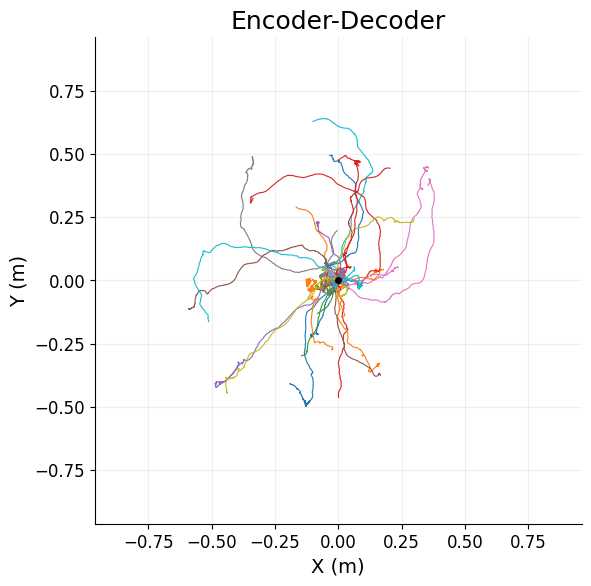

Saved trajectory_prior_deterministic


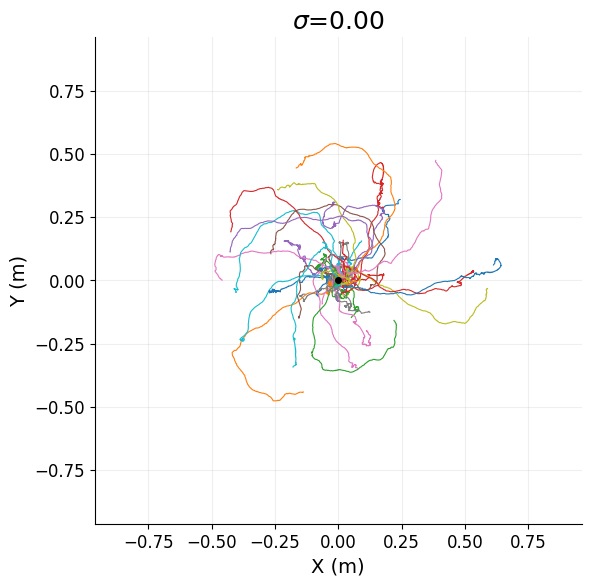

Saved trajectory_prior_logvar_-0.5


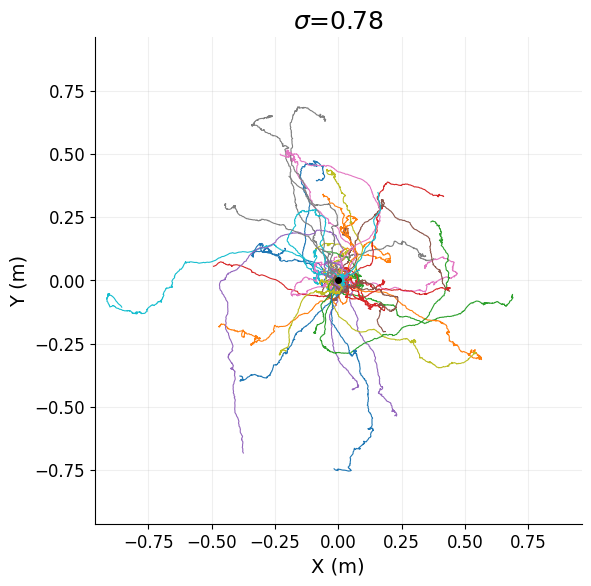

Saved trajectory_prior_logvar_-1


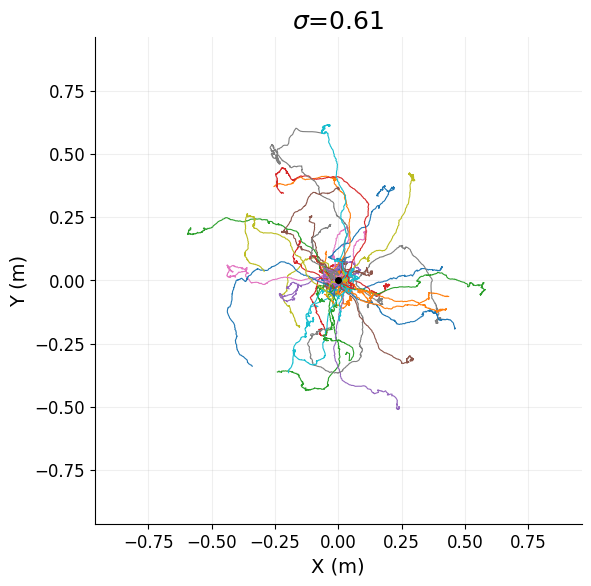

Saved trajectory_prior_logvar_-2


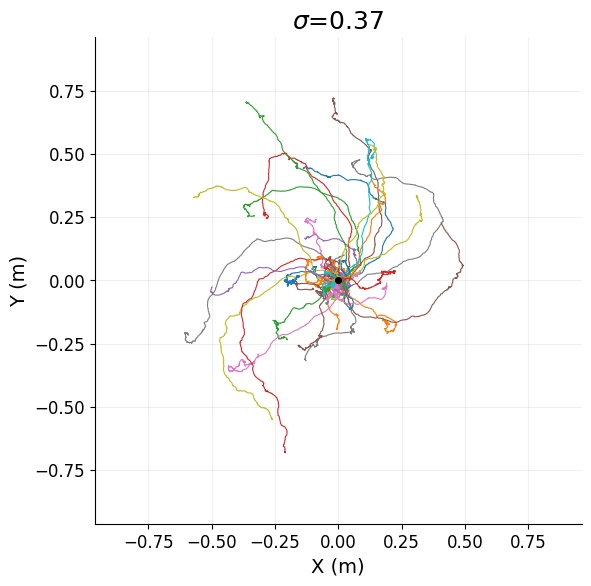

Saved trajectory_prior_logvar_-3


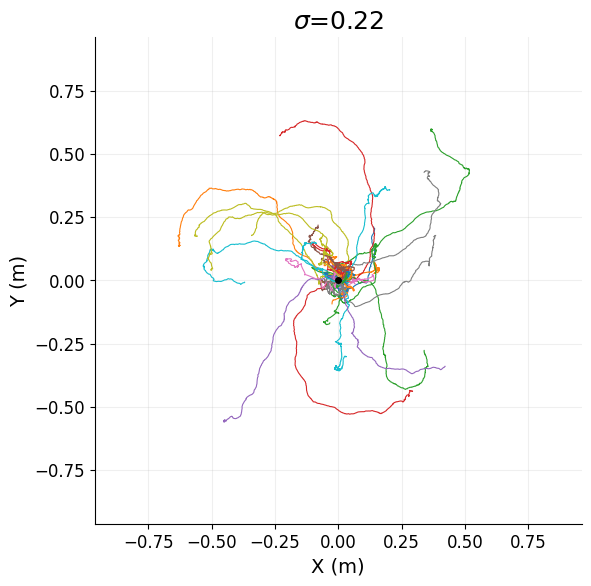

Saved trajectory_prior_logvar_-4


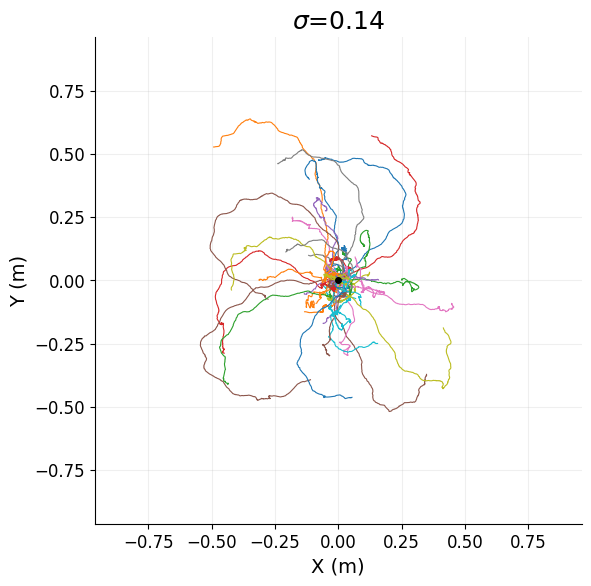

Saved trajectory_prior_logvar_0


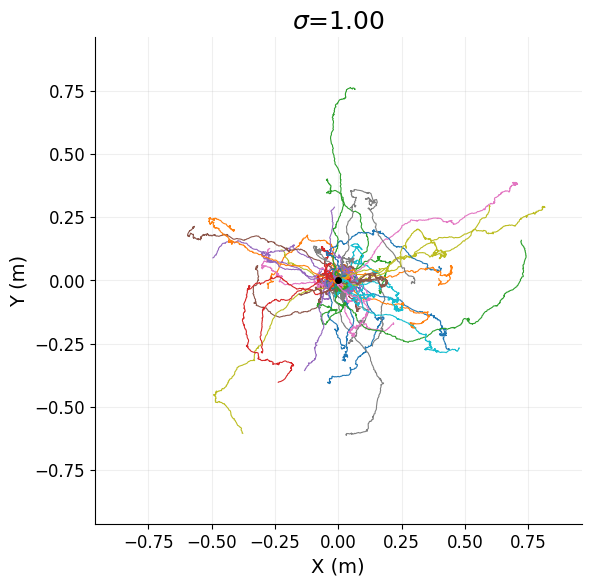

Saved trajectory_prior_predicted_logvar


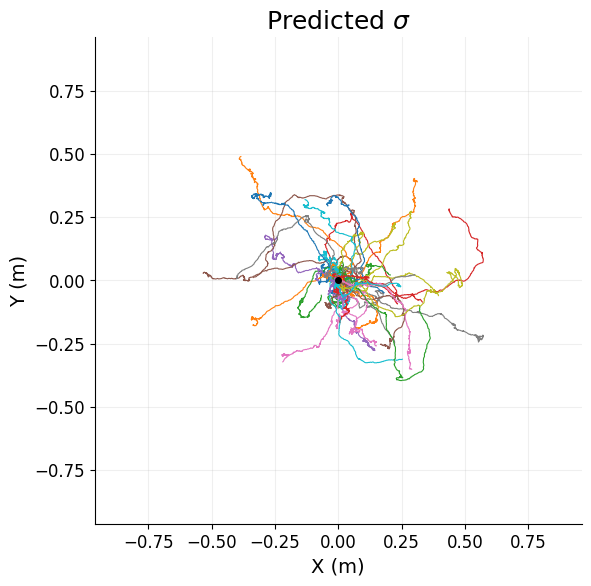

In [19]:
# Separate plot for each dataset
SAVE_DIR.mkdir(parents=True, exist_ok=True)

for name in datasets_to_plot:
    xy = trajectories[name]
    label = LABEL_MAP.get(name, name)
    safe_name = name.replace("_qpos", "")

    fig, ax = plt.subplots(figsize=(6, 6))

    for i in range(len(xy)):
        ax.plot(xy[i, :, 0], xy[i, :, 1], alpha=1.0, linewidth=0.8)

    ax.plot(0, 0, "ko", markersize=4, zorder=5)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_title(label, fontsize=18)
    ax.set_xlabel("X (m)", fontsize=14)
    ax.set_ylabel("Y (m)", fontsize=14)
    ax.tick_params(labelsize=12)
    ax.grid(True, alpha=0.2)
    sns.despine(ax=ax)

    plt.tight_layout()
    for fmt in ("pdf", "svg", "png"):
        fig.savefig(
            SAVE_DIR / f"trajectory_{safe_name}.{fmt}", bbox_inches="tight", dpi=150
        )
    print(f"Saved trajectory_{safe_name}")
    plt.show()